# Getting the PAL data

This notebook gets the acoustic (PAL) data of a BGC-Argo float into two
tables, with no further processing:

- **park**: one row per acoustic measurement during the park drift, with
  every frequency band the float sent, and the float's CTD/BGC data and
  position at that time;
- **profiles**: the float's CTD/BGC profiles.

No depth correction, no wind speed, and no despiking: the band levels are
the ones the float sent, which is what is needed to look at other sounds
than wind, e.g. ships or marine mammals.  The
[ArgoPAL tutorial](argopal_tutorial.ipynb) goes on to wind speed.

Float **7902280** (Ligurian Sea, 2026).

In [1]:
import warnings

import matplotlib.pyplot as plt

import argopal

warnings.simplefilter("ignore")

## 1. Download the files

Two sets of files from the Argo GDAC: the **aux** files, which hold the
acoustic spectra and the hydrophone configuration, and the **core** files
(trajectory, profiles, metadata).  They are saved in `argopal_data/7902280/`
and only downloaded again when the GDAC copy is newer.

In [2]:
files = argopal.download_aux(7902280, verbose=False)
files |= argopal.download_core(7902280, verbose=False)
sorted(files)

['7902280_Rtraj.nc',
 '7902280_Rtraj_aux.nc',
 '7902280_Sprof.nc',
 '7902280_meta.nc',
 '7902280_meta_aux.nc',
 '7902280_tech_aux.nc']

## 2. Read the acoustic spectra

`read_pal` gives one row per acoustic measurement: `cycle`,
`measurement_code`, `datetime`, `pressure`, and one column per band,
`f_63Hz` … `f_25000Hz`.

In [3]:
meta = argopal.read_pal_meta(files["7902280_meta_aux.nc"])
pal = argopal.read_pal(files["7902280_Rtraj_aux.nc"], meta=meta)
pal.head()

,cycle,measurement_code,datetime,pressure,f_63Hz,f_100Hz,f_125Hz,f_160Hz,f_400Hz,f_500Hz,...,f_10000Hz,f_12500Hz,f_16000Hz,f_20000Hz,f_25000Hz,spectrum_qc,variance_class_1,variance_class_2,variance_class_3,variance_class_4
0,1,290,2026-01-12 04:48:59.446877696,974.700012,86.5,84.0,80.5,78.5,66.5,63.5,...,44.5,41.0,40.5,40.5,36.5,0,NaN,NaN,NaN,NaN
1,1,290,2026-01-12 04:59:00.433076736,986.700012,86.0,81.5,77.5,75.5,66.5,63.5,...,44.5,40.5,40.0,39.5,36.0,0,NaN,NaN,NaN,NaN
2,1,290,2026-01-12 05:09:01.419275776,993.799988,88.0,81.5,78.0,76.0,66.0,63.5,...,44.5,40.5,40.0,39.5,36.0,0,NaN,NaN,NaN,NaN
3,1,290,2026-01-12 05:19:02.405474304,996.000000,86.5,81.5,79.0,76.0,67.0,65.5,...,44.5,40.5,40.0,39.0,36.0,0,NaN,NaN,NaN,NaN
4,1,290,2026-01-12 05:29:03.391673856,995.900024,89.0,85.0,81.5,78.5,67.0,63.5,...,44.5,40.5,39.5,39.0,35.5,0,NaN,NaN,NaN,NaN


The PAL sends either 23 bands or a 9-band subset; this float sends mostly
9 bands, so the other columns are nearly empty.  Whether the band levels
were divided by the bandwidth on board is in the hydrophone
configuration: here they were, so the values are spectral levels
(dB re 1 µPa² Hz⁻¹) at the hydrophone's depth.

In [4]:
print("spectra by number of bands:", pal.attrs["band_layout_counts"])
print("bands with data (Hz):", argopal.available_bands(pal))
print("normalised by bandwidth on board:", meta["band_normalization"])
print("measurement codes:", sorted(pal["measurement_code"].unique().tolist()))

spectra by number of bands: {'23': 306, '9': 71830, 'other': 0}
bands with data (Hz): [63, 125, 400, 1000, 2000, 5000, 8000, 12500, 20000]
normalised by bandwidth on board: True
measurement codes: [290]


This float records acoustics during the park drift only (measurement code
290).  A float that also records during descent or ascent would show other
codes here; `clean_pal(..., measurement_codes=...)` keeps them.

## 3. Keep the bands with data, and clean

`select_bands(pal, bands="all")` keeps every band that holds data;
`bands=(1000, 8000)` would keep only those.  `clean_pal` keeps the park
drift and drops spectra with a bad QC flag.

Despiking is **off** here (`despike_spectra=False`): it removes short,
loud events, which is right for wind but removes ships passing or
marine-mammal sounds.

In [5]:
pal = argopal.select_bands(pal, bands="all")
park = argopal.clean_pal(pal, despike_spectra=False)
print(len(park), "measurements;", park.attrs["clean"])

72136 measurements; {'measurement_codes': [290], 'bad_qc': ['3', '4', '9'], 'removed_measurement_code': 0, 'removed_bad_qc': 0}


One cycle, every band: the measurements are 5 min apart, and the short
peaks are what despiking would remove.

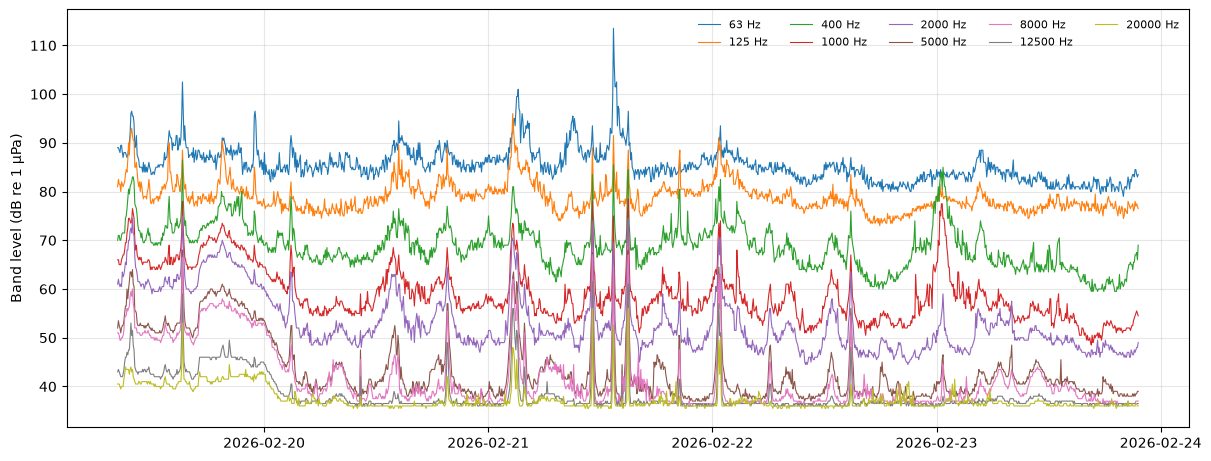

In [6]:
one = park[park["cycle"] == 10]
fig, ax = plt.subplots(figsize=(12, 4.5), layout="constrained")
for f in park.attrs["bands_hz"]:
    ax.plot(one["datetime"], one[f"f_{f}Hz"], lw=0.8, label=f"{f:g} Hz")
ax.set_ylabel("Band level (dB re 1 µPa)")
ax.legend(ncol=5, fontsize=8, frameon=False)
ax.grid(alpha=0.3)

## 4. Add the CTD/BGC data and positions

The park-drift CTD/BGC samples are interpolated in time onto each acoustic
measurement (within a cycle, between samples at most 2 h apart), and the
position between the surface fixes before and after.

`mode` chooses which Argo values are used, with no mixing: `"delayed"`
(quality-controlled, the default), `"adjusted"` or `"raw"`.  This float is
recent, so its park data are not in delayed mode yet:

In [7]:
park_delayed = argopal.read_park(files["7902280_Rtraj.nc"], mode="delayed")
park_raw = argopal.read_park(files["7902280_Rtraj.nc"], mode="raw")
print("park temperature, delayed mode:", park_delayed["TEMP"].notna().sum(), "values")
print("park temperature, raw:", park_raw["TEMP"].notna().sum(), "values")

park temperature, delayed mode: 0 values
park temperature, raw: 6091 values


So raw values here (each column `X` comes with `X_qc` and `X_data_mode`,
to filter on later):

In [8]:
park = argopal.attach_park(park, park_raw)
park = argopal.attach_positions(
    park, argopal.read_positions(files["7902280_Rtraj.nc"])
)
park[["datetime", "pressure", "f_1000Hz", "f_8000Hz", "TEMP", "PSAL",
      "DOXY", "latitude", "longitude"]].head()

,datetime,pressure,f_1000Hz,f_8000Hz,TEMP,PSAL,DOXY,latitude,longitude
0,2026-01-12 04:48:59.446877696,974.700012,58.5,48.0,13.461872,38.583991,NaN,43.752416,9.103861
1,2026-01-12 04:59:00.433076736,986.700012,58.0,47.5,13.460186,38.583491,NaN,43.752426,9.103781
2,2026-01-12 05:09:01.419275776,993.799988,58.5,47.5,13.458500,38.582990,NaN,43.752437,9.103701
3,2026-01-12 05:19:02.405474304,996.000000,58.5,47.5,13.456814,38.582490,NaN,43.752448,9.103621
4,2026-01-12 05:29:03.391673856,995.900024,58.5,47.5,13.455128,38.581989,NaN,43.752458,9.103541


## 5. The profiles

One row per profile level, every variable with its QC flag and data mode,
in the same data mode:

In [9]:
profiles = argopal.read_profiles(files["7902280_Sprof.nc"], mode="raw")
print(profiles["cycle"].nunique(), "profiles")
profiles.head()

77 profiles


,cycle,direction,datetime,latitude,longitude,position_qc,PRES,PRES_qc,PRES_data_mode,TEMP,...,TEMP_data_mode,PSAL,PSAL_qc,PSAL_data_mode,DOXY,DOXY_qc,DOXY_data_mode,PH_IN_SITU_TOTAL,PH_IN_SITU_TOTAL_qc,PH_IN_SITU_TOTAL_data_mode
0,1,A,2026-01-13 10:02:08.031323136,43.754299,9.089642,1,0.11,1,R,14.72300,...,R,38.230000,3,R,220.733932,3,R,8.037354,3,R
1,1,A,2026-01-13 10:02:08.031323136,43.754299,9.089642,1,0.40,1,R,14.72300,...,R,38.230000,3,R,220.489227,3,R,8.037354,3,R
2,1,A,2026-01-13 10:02:08.031323136,43.754299,9.089642,1,0.41,1,R,14.72300,...,R,38.230000,3,R,NaN,,,NaN,,
3,1,A,2026-01-13 10:02:08.031323136,43.754299,9.089642,1,0.50,1,R,14.72354,...,R,38.228649,3,R,NaN,,,8.038637,3,R
4,1,A,2026-01-13 10:02:08.031323136,43.754299,9.089642,1,0.60,1,R,14.72414,...,R,38.227150,3,R,NaN,,,8.038179,3,R


## 6. A first look

Daily median of each band over the deployment, and the median spectrum:

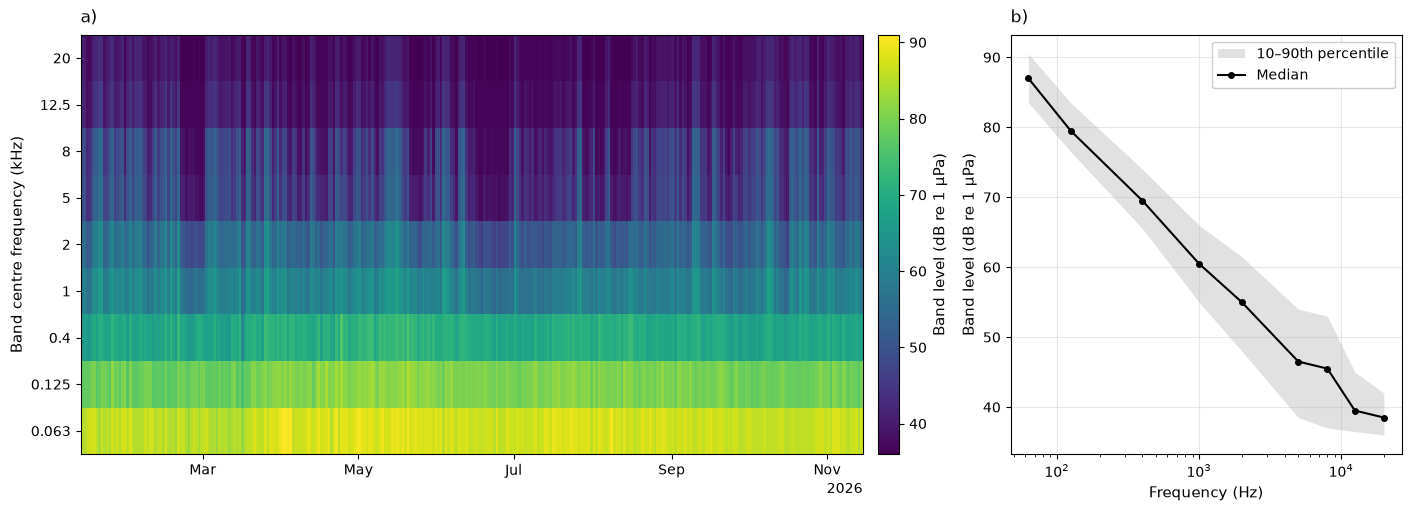

In [10]:
fig, axes = argopal.plot_pal_spectra(park)

## 7. Save

Both tables as CSV files, or in one NetCDF file (one group per table, with
the processing record as attributes):

In [11]:
tables = {"park": park, "profiles": profiles}
argopal.export(tables, "output/wmo7902280", format="csv")

['output/wmo7902280_park.csv', 'output/wmo7902280_profiles.csv']

In [12]:
argopal.export(tables, "output/wmo7902280.nc", format="netcdf")

['output/wmo7902280.nc']

Every column is described on the
[Outputs](https://argopal.readthedocs.io/en/latest/outputs.html) page.  To
go on to the depth correction and wind speed, see the
[ArgoPAL tutorial](argopal_tutorial.ipynb), or `argopal.process_float`.